<a href="https://colab.research.google.com/github/KyleRed16/Herbert-vs-Allen/blob/main/Herbert_vs_Allen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install nflreadpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [nflreadpy]


In [7]:
import nflreadpy as nfl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pbp = nfl.load_pbp(
    seasons=[2021, 2022, 2023, 2024, 2025]
).to_pandas()

print("Dataset dimensions:", pbp.shape)

pbp = pbp[
    pbp["season_type"].eq("REG")
].copy()

print("Regular season dimensions:", pbp.shape)

print(pbp["season"].value_counts().sort_index())

Dataset dimensions: (247284, 372)
Regular season dimensions: (235933, 372)
season
2021    47651
2022    47157
2023    47399
2024    47274
2025    46452
Name: count, dtype: int64


Same data set as last time, 372 columns with 247284 rows from 2021 to 2025, dropped to 235933 for only regular season entries. Some 2026 values may be added later for midseason comparisons towards the end of this project.

In [8]:
# Inspect quarterback names
print("HERBERT — PASSER")
print(
    pbp.loc[
        pbp["passer_player_name"].str.contains(
            "Herbert", case=False, na=False
        ),
        "passer_player_name"
    ].value_counts()
)

print("\nALLEN — PASSER")
print(
    pbp.loc[
        pbp["passer_player_name"].str.contains(
            "Allen", case=False, na=False
        ),
        "passer_player_name"
    ].value_counts()
)

print("\nHERBERT — RUSHER")
print(
    pbp.loc[
        pbp["rusher_player_name"].str.contains(
            "Herbert", case=False, na=False
        ),
        "rusher_player_name"
    ].value_counts()
)

print("\nALLEN — RUSHER")
print(
    pbp.loc[
        pbp["rusher_player_name"].str.contains(
            "Allen", case=False, na=False
        ),
        "rusher_player_name"
    ].value_counts()
)

HERBERT — PASSER
passer_player_name
J.Herbert    3048
Name: count, dtype: int64

ALLEN — PASSER
passer_player_name
J.Allen      2844
K.Allen       115
B.Allen       106
Jos.Allen      44
Name: count, dtype: int64

HERBERT — RUSHER
rusher_player_name
K.Herbert    417
J.Herbert    323
Name: count, dtype: int64

ALLEN — RUSHER
rusher_player_name
J.Allen      570
B.Allen      124
K.Allen       27
L.Allen       23
Jos.Allen      4
M.Allen        1
Name: count, dtype: int64


Here we are looking at the dataset enteries and which Herberts and Allens are included for passer and rusher IDs.

In [9]:
print("Play types:")
print(pbp["play_type"].value_counts(dropna=False))

print("\nQB dropbacks:")
print(pbp["qb_dropback"].value_counts(dropna=False))

print("\nQB scrambles:")
print(pbp["qb_scramble"].value_counts(dropna=False))

print("\nEPA columns:")
print([
    col for col in pbp.columns
    if "epa" in col.lower()
])

Play types:
play_type
pass           97026
run            71255
no_play        22533
kickoff        13784
punt           10520
None            6895
extra_point     6138
field_goal      5352
qb_kneel        2085
qb_spike         345
Name: count, dtype: int64

QB dropbacks:
qb_dropback
0.0    127012
1.0    102026
NaN      6895
Name: count, dtype: int64

QB scrambles:
qb_scramble
0.0    230577
1.0      5356
Name: count, dtype: int64

EPA columns:
['epa', 'total_home_epa', 'total_away_epa', 'total_home_rush_epa', 'total_away_rush_epa', 'total_home_pass_epa', 'total_away_pass_epa', 'air_epa', 'yac_epa', 'comp_air_epa', 'comp_yac_epa', 'total_home_comp_air_epa', 'total_away_comp_air_epa', 'total_home_comp_yac_epa', 'total_away_comp_yac_epa', 'total_home_raw_air_epa', 'total_away_raw_air_epa', 'total_home_raw_yac_epa', 'total_away_raw_yac_epa', 'qb_epa', 'xyac_epa']


Here we inspect the play classifications, including play types, dropbacks, scrambles, and all EPA columns.

In [10]:
qbs = {
    "Herbert": "J.Herbert",
    "Allen": "J.Allen"
}

for qb, name in qbs.items():

    qb_plays = pbp[
        (pbp["passer_player_name"] == name) |
        (pbp["rusher_player_name"] == name)
    ].copy()

    print(f"\n{'='*35}")
    print(qb)
    print(f"{'='*35}")

    print("Total identified plays:", len(qb_plays))

    print("\nPlay type:")
    print(qb_plays["play_type"].value_counts(dropna=False))

    print("\nDropbacks:")
    print(qb_plays["qb_dropback"].value_counts(dropna=False))

    print("\nScrambles:")
    print(qb_plays["qb_scramble"].value_counts(dropna=False))

    print("\nSacks:")
    print(qb_plays["sack"].value_counts(dropna=False))


Herbert
Total identified plays: 3371

Play type:
play_type
pass        3042
run          252
qb_kneel      71
qb_spike       6
Name: count, dtype: int64

Dropbacks:
qb_dropback
1.0    3211
0.0     160
Name: count, dtype: int64

Scrambles:
qb_scramble
0.0    3202
1.0     169
Name: count, dtype: int64

Sacks:
sack
0.0    3178
1.0     193
Name: count, dtype: int64

Allen
Total identified plays: 3414

Play type:
play_type
pass        2839
run          506
qb_kneel      64
qb_spike       5
Name: count, dtype: int64

Dropbacks:
qb_dropback
1.0    3073
0.0     341
Name: count, dtype: int64

Scrambles:
qb_scramble
0.0    3180
1.0     234
Name: count, dtype: int64

Sacks:
sack
0.0    3277
1.0     137
Name: count, dtype: int64


In [11]:
columns_to_inspect = [
    "season",
    "week",
    "game_id",
    "play_id",
    "posteam",
    "play_type",
    "passer_player_name",
    "rusher_player_name",
    "qb_dropback",
    "qb_scramble",
    "sack",
    "pass_attempt",
    "rush_attempt",
    "epa",
    "qb_epa",
    "desc"
]

herbert_examples = pbp[
    (pbp["passer_player_name"] == "J.Herbert") |
    (pbp["rusher_player_name"] == "J.Herbert")
]

allen_examples = pbp[
    (pbp["passer_player_name"] == "J.Allen") |
    (pbp["rusher_player_name"] == "J.Allen")
]

display(herbert_examples[columns_to_inspect].head(15))
display(allen_examples[columns_to_inspect].head(15))

,season,week,game_id,play_id,posteam,play_type,passer_player_name,rusher_player_name,qb_dropback,qb_scramble,sack,pass_attempt,rush_attempt,epa,qb_epa,desc
1425,2021,1,2021_01_LAC_WAS,56.0,LAC,pass,J.Herbert,None,1.0,0.0,0.0,1.0,0.0,0.490810,0.490810,(15:00) (Shotgun) 10-J.Herbert pass short left...
1426,2021,1,2021_01_LAC_WAS,85.0,LAC,pass,J.Herbert,None,1.0,0.0,0.0,1.0,0.0,0.310640,0.310640,(14:32) (Shotgun) 10-J.Herbert pass short righ...
1428,2021,1,2021_01_LAC_WAS,130.0,LAC,pass,J.Herbert,None,1.0,0.0,0.0,1.0,0.0,0.629552,0.629552,(13:29) (Shotgun) 10-J.Herbert pass short left...
1430,2021,1,2021_01_LAC_WAS,175.0,LAC,pass,J.Herbert,None,1.0,0.0,0.0,1.0,0.0,0.586050,0.586050,(12:12) (Shotgun) 10-J.Herbert pass short righ...
1432,2021,1,2021_01_LAC_WAS,225.0,LAC,pass,J.Herbert,None,1.0,0.0,0.0,1.0,0.0,-0.904084,-0.904084,(10:58) 10-J.Herbert pass short left to 87-J.C...
1434,2021,1,2021_01_LAC_WAS,272.0,LAC,pass,J.Herbert,None,1.0,0.0,0.0,1.0,0.0,1.871675,1.871675,(9:57) (Shotgun) 10-J.Herbert pass short middl...
1442,2021,1,2021_01_LAC_WAS,450.0,LAC,pass,J.Herbert,None,1.0,0.0,0.0,1.0,0.0,-0.498681,-0.498681,(7:35) 10-J.Herbert pass incomplete short left...
1444,2021,1,2021_01_LAC_WAS,493.0,LAC,pass,J.Herbert,None,1.0,0.0,0.0,1.0,0.0,-0.872887,-0.872887,(6:55) (Shotgun) 10-J.Herbert pass short left ...
1453,2021,1,2021_01_LAC_WAS,711.0,LAC,pass,J.Herbert,None,1.0,0.0,0.0,1.0,0.0,0.593156,0.593156,(2:52) 79-T.Pipkins reported in as eligible. 1...
1454,2021,1,2021_01_LAC_WAS,742.0,LAC,pass,J.Herbert,None,1.0,0.0,0.0,1.0,0.0,-0.459665,-0.459665,(2:22) (Shotgun) 10-J.Herbert pass incomplete ...


,season,week,game_id,play_id,posteam,play_type,passer_player_name,rusher_player_name,qb_dropback,qb_scramble,sack,pass_attempt,rush_attempt,epa,qb_epa,desc
2334,2021,1,2021_01_PIT_BUF,63.0,BUF,pass,J.Allen,None,1.0,0.0,0.0,1.0,0.0,0.264682,0.264682,(14:47) (Shotgun) 17-J.Allen pass short right ...
2335,2021,1,2021_01_PIT_BUF,87.0,BUF,pass,J.Allen,None,1.0,0.0,0.0,1.0,0.0,-0.906025,-0.906025,"(14:14) (No Huddle, Shotgun) 17-J.Allen pass s..."
2336,2021,1,2021_01_PIT_BUF,111.0,BUF,pass,J.Allen,None,1.0,0.0,0.0,1.0,0.0,-1.550143,-1.550143,"(13:40) (No Huddle, Shotgun) 17-J.Allen pass i..."
2348,2021,1,2021_01_PIT_BUF,382.0,BUF,pass,J.Allen,None,1.0,0.0,0.0,1.0,0.0,-0.174705,-0.174705,(9:04) (Shotgun) 17-J.Allen pass short right t...
2349,2021,1,2021_01_PIT_BUF,406.0,BUF,pass,J.Allen,None,1.0,0.0,0.0,1.0,0.0,-0.119813,-0.119813,(8:24) (Shotgun) 17-J.Allen pass short left to...
2350,2021,1,2021_01_PIT_BUF,430.0,BUF,pass,J.Allen,None,1.0,0.0,0.0,1.0,0.0,1.849798,1.849798,(7:47) (Shotgun) 17-J.Allen pass short right t...
2351,2021,1,2021_01_PIT_BUF,454.0,BUF,pass,J.Allen,None,1.0,0.0,0.0,1.0,0.0,-0.446584,-0.446584,(7:04) (Shotgun) 17-J.Allen pass incomplete sh...
2352,2021,1,2021_01_PIT_BUF,476.0,BUF,pass,J.Allen,None,1.0,0.0,0.0,1.0,0.0,1.278781,1.278781,(7:00) (Shotgun) 17-J.Allen pass deep left to ...
2355,2021,1,2021_01_PIT_BUF,561.0,BUF,pass,J.Allen,None,1.0,0.0,0.0,1.0,0.0,-0.810268,-0.810268,(5:28) (Shotgun) 17-J.Allen pass incomplete de...
2356,2021,1,2021_01_PIT_BUF,589.0,BUF,pass,J.Allen,None,1.0,0.0,0.0,1.0,0.0,-1.077856,-1.077856,(5:21) (Shotgun) 17-J.Allen pass incomplete de...


In [12]:
for qb, name in qbs.items():

    qb_plays = pbp[
        (pbp["passer_player_name"] == name) |
        (pbp["rusher_player_name"] == name)
    ].copy()

    print(f"\n{qb} — PLAY CLASSIFICATION")

    display(
        pd.crosstab(
            qb_plays["play_type"],
            [
                qb_plays["qb_dropback"],
                qb_plays["qb_scramble"]
            ],
            margins=True
        )
    )


Herbert — PLAY CLASSIFICATION


qb_dropback  0.0   1.0        All
qb_scramble  0.0   0.0  1.0      
play_type                        
pass           0  3042    0  3042
qb_kneel      71     0    0    71
qb_spike       6     0    0     6
run           83     0  169   252
All          160  3042  169  3371


Allen — PLAY CLASSIFICATION


qb_dropback  0.0   1.0        All
qb_scramble  0.0   0.0  1.0      
play_type                        
pass           0  2839    0  2839
qb_kneel      64     0    0    64
qb_spike       5     0    0     5
run          272     0  234   506
All          341  2839  234  3414

In the previous cells, we have split the Herbert and Allen data apart and viewed how many entries each QB has. Right away, we can compare Allen's greater rushing involvement, Herbert's greater amount of sacks, and that play volume is similar across the 5 season stretch.

In [13]:
for qb, name in qbs.items():

    qb_plays = pbp[
        (pbp["passer_player_name"] == name) |
        (pbp["rusher_player_name"] == name)
    ].copy()

    qb_plays["epa_difference"] = (
        qb_plays["epa"] - qb_plays["qb_epa"]
    )

    print(f"\n{qb}")

    print(
        qb_plays["epa_difference"]
        .describe()
    )

    print(
        "Records with different EPA:",
        (qb_plays["epa_difference"].abs() > 1e-9).sum()
    )


Herbert
count    3371.000000
mean       -0.016178
std         0.264406
min        -5.860452
25%         0.000000
50%         0.000000
75%         0.000000
max         0.000000
Name: epa_difference, dtype: float64
Records with different EPA: 13

Allen
count    3414.000000
mean       -0.011078
std         0.220421
min        -6.006662
25%         0.000000
50%         0.000000
75%         0.000000
max         0.000000
Name: epa_difference, dtype: float64
Records with different EPA: 9


In [14]:
for qb, name, team in [
    ("Herbert", "J.Herbert", "LAC"),
    ("Allen", "J.Allen", "BUF")
]:

    qb_plays = pbp[
        (pbp["passer_player_name"] == name) |
        (pbp["rusher_player_name"] == name)
    ].copy()

    print(f"\n{qb} team verification")

    print(qb_plays["posteam"].value_counts(dropna=False))

    print(
        "Unexpected team records:",
        len(qb_plays[qb_plays["posteam"] != team])
    )

    print(
        "Duplicate play records:",
        qb_plays.duplicated(["game_id", "play_id"]).sum()
    )


Herbert team verification
posteam
LAC    3371
Name: count, dtype: int64
Unexpected team records: 0
Duplicate play records: 0

Allen team verification
posteam
BUF    3414
Name: count, dtype: int64
Unexpected team records: 0
Duplicate play records: 0


Above, we check EPA attribution (whether epa and qb_epa differ) and verify team consistency to establish cleaning ground rules.

In [15]:
def build_qb_dataset(pbp, qb_name):

    qb_plays = pbp[
        (pbp["passer_player_name"] == qb_name) |
        (pbp["rusher_player_name"] == qb_name)
    ].copy()

    # Identify the three qualifying play categories
    qb_plays["is_dropback"] = (
        qb_plays["qb_dropback"] == 1
    )

    qb_plays["is_scramble"] = (
        (qb_plays["play_type"] == "run") &
        (qb_plays["qb_scramble"] == 1)
    )

    qb_plays["is_designed_run"] = (
        (qb_plays["play_type"] == "run") &
        (qb_plays["rusher_player_name"] == qb_name) &
        (qb_plays["qb_scramble"] == 0) &
        (qb_plays["rush_attempt"] == 1)
    )

    # Keep qualifying QB plays
    qb_plays["include_in_analysis"] = (
        qb_plays["is_dropback"] |
        qb_plays["is_scramble"] |
        qb_plays["is_designed_run"]
    )

    analysis_plays = qb_plays[
        qb_plays["include_in_analysis"]
    ].copy()

    return analysis_plays

Now, building our reusable function for cleaning. Each play recieves a classification flag, making it easier to audit our selections, calculate position-specific statistics, and reuse the same definitions in later phases.

In [16]:
qb_data = {}

for qb, name in qbs.items():

    qb_data[qb] = build_qb_dataset(pbp, name)

    print(f"\n{qb}")
    print("Qualifying plays:", len(qb_data[qb]))

    print(
        qb_data[qb][
            ["is_dropback", "is_scramble", "is_designed_run"]
        ].sum()
    )


Herbert
Qualifying plays: 3294
is_dropback        3211
is_scramble         169
is_designed_run      83
dtype: int64

Allen
Qualifying plays: 3345
is_dropback        3073
is_scramble         234
is_designed_run     272
dtype: int64


Proving the function works, and its worth noting that scrambles are included in dropbacks, so qualifying plays only equals dropbacks + designed runs.

In [17]:
season_summary = []

for qb, data in qb_data.items():

    summary = (
        data.groupby("season")
        .agg(
            total_qb_epa=("qb_epa", "sum"),
            qb_plays=("qb_epa", "count"),
            designed_runs=("is_designed_run", "sum")
        )
        .reset_index()
    )

    summary["qb"] = qb

    summary["epa_per_play"] = (
        summary["total_qb_epa"] / summary["qb_plays"]
    )

    season_summary.append(summary)

season_summary = pd.concat(
    season_summary,
    ignore_index=True
)

display(
    season_summary[
        [
            "season",
            "qb",
            "total_qb_epa",
            "qb_plays",
            "designed_runs",
            "epa_per_play"
        ]
    ].round(3)
)

,season,qb,total_qb_epa,qb_plays,designed_runs,epa_per_play
0,2021,Herbert,135.162,759,14,0.178
1,2022,Herbert,39.691,773,15,0.051
2,2023,Herbert,37.348,528,11,0.071
3,2024,Herbert,73.960,594,18,0.125
4,2025,Herbert,42.589,640,25,0.067
5,2021,Allen,109.940,739,64,0.149
6,2022,Allen,143.198,708,57,0.202
7,2023,Allen,135.850,707,54,0.192
8,2024,Allen,162.196,591,51,0.274
9,2025,Allen,106.564,600,46,0.178


Results: We can see that Herbert produced a higher EPA per play in his best season (2021) but Allen produces better season-by-season results and tops Herbert in every year since.

In [18]:
comparison = (
    season_summary
    .pivot(
        index="season",
        columns="qb",
        values="epa_per_play"
    )
    .reset_index()
)

comparison["epa_gap"] = (
    comparison["Allen"] - comparison["Herbert"]
)

comparison["higher_epa"] = np.where(
    comparison["epa_gap"] > 0,
    "Allen",
    "Herbert"
)

display(comparison.round(3))

qb,season,Allen,Herbert,epa_gap,higher_epa
0,2021,0.149,0.178,-0.029,Herbert
1,2022,0.202,0.051,0.151,Allen
2,2023,0.192,0.071,0.121,Allen
3,2024,0.274,0.125,0.150,Allen
4,2025,0.178,0.067,0.111,Allen


Allen outperforms Herbert by more than 0.11 EPA per play in 2022 through 2025.

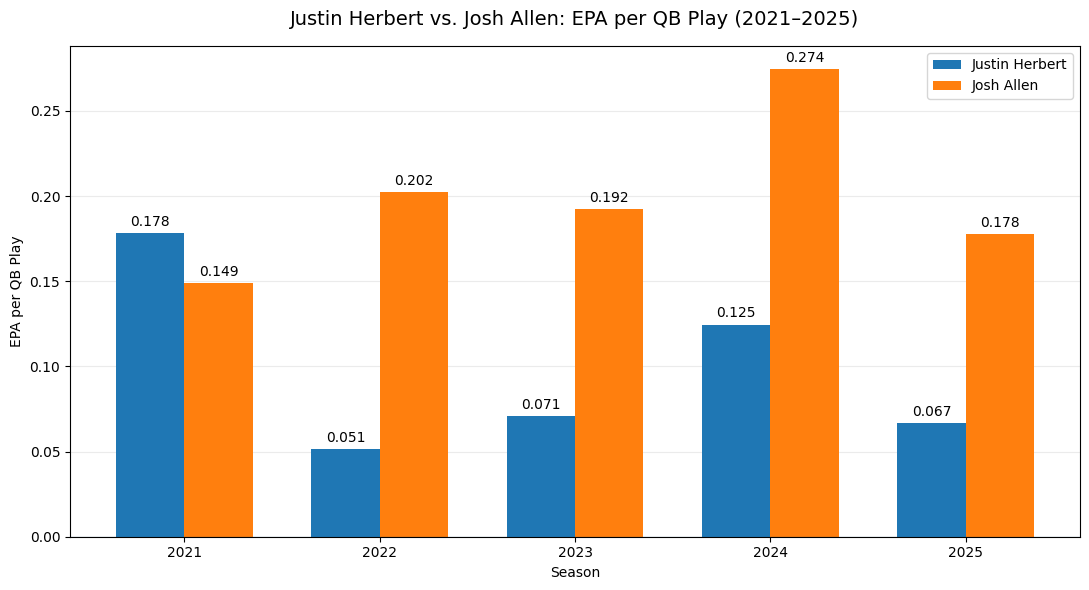

In [20]:
seasons = comparison["season"]

x = np.arange(len(seasons))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars1 = ax.bar(
    x - width / 2,
    comparison["Herbert"],
    width,
    label="Justin Herbert"
)

bars2 = ax.bar(
    x + width / 2,
    comparison["Allen"],
    width,
    label="Josh Allen"
)

ax.set_title(
    "Justin Herbert vs. Josh Allen: EPA per QB Play (2021–2025)",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Season")
ax.set_ylabel("EPA per QB Play")

ax.set_xticks(x)
ax.set_xticklabels(seasons)

ax.axhline(0, linewidth=0.8)
ax.legend()

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

ax.bar_label(bars1, fmt="%.3f", padding=3)
ax.bar_label(bars2, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()

In [21]:
overall_summary = []

for qb, data in qb_data.items():

    total_epa = data["qb_epa"].sum()
    total_plays = data["qb_epa"].count()

    pooled_epa = total_epa / total_plays

    seasonal_average = (
        season_summary[
            season_summary["qb"] == qb
        ]["epa_per_play"].mean()
    )

    overall_summary.append({
        "qb": qb,
        "total_qb_epa": total_epa,
        "total_plays": total_plays,
        "pooled_epa_per_play": pooled_epa,
        "average_season_epa": seasonal_average
    })

overall_summary = pd.DataFrame(overall_summary)

display(overall_summary.round(3))

,qb,total_qb_epa,total_plays,pooled_epa_per_play,average_season_epa
0,Herbert,328.750,3294,0.100,0.098
1,Allen,657.747,3345,0.197,0.199


Now we can look at the pooled EPA per play, meaning that we are taking the QBs EPA per play across all of the seasons and comparing it to the average per season. Herbert's 2021 season raises his average, but Josh Allen's consistency continues to top it by 0.097. This does not isolate the QB's ability from supporting casts, offensive schemes, opponents, or game situations.

In [22]:
game_summary = {}

for qb, data in qb_data.items():

    game_summary[qb] = (
        data.groupby(["season", "game_id"])
        .agg(
            total_epa=("qb_epa", "sum"),
            total_plays=("qb_epa", "count")
        )
        .reset_index()
    )

    game_summary[qb]["epa_per_play"] = (
        game_summary[qb]["total_epa"] /
        game_summary[qb]["total_plays"]
    )

    print(f"\n{qb}")
    print("Games:", len(game_summary[qb]))
    print("Total plays:", game_summary[qb]["total_plays"].sum())
    print("Average plays per game:",
          round(game_summary[qb]["total_plays"].mean(), 1))


Herbert
Games: 80
Total plays: 3294
Average plays per game: 41.2

Allen
Games: 81
Total plays: 3345
Average plays per game: 41.3


Now onto bootstrapping confidence intervals. We want to sample random games from each quarterback and compare with a 95% confidence interval. First, we aggregate players by game so each row represents one quarterback's performance in the individual game.

In [23]:
def bootstrap_epa_gap(
    herbert_games,
    allen_games,
    iterations=10000,
    seed=42
):

    rng = np.random.default_rng(seed)

    bootstrap_gaps = []

    for _ in range(iterations):

        herbert_sample = herbert_games.iloc[
            rng.integers(
                0, len(herbert_games),
                size=len(herbert_games)
            )
        ]

        allen_sample = allen_games.iloc[
            rng.integers(
                0, len(allen_games),
                size=len(allen_games)
            )
        ]

        herbert_epa = (
            herbert_sample["total_epa"].sum() /
            herbert_sample["total_plays"].sum()
        )

        allen_epa = (
            allen_sample["total_epa"].sum() /
            allen_sample["total_plays"].sum()
        )

        bootstrap_gaps.append(
            allen_epa - herbert_epa
        )

    bootstrap_gaps = np.array(bootstrap_gaps)

    lower = np.percentile(bootstrap_gaps, 2.5)
    upper = np.percentile(bootstrap_gaps, 97.5)

    return {
        "observed_gap": (
            overall_summary.loc[
                overall_summary["qb"] == "Allen",
                "pooled_epa_per_play"
            ].iloc[0]
            -
            overall_summary.loc[
                overall_summary["qb"] == "Herbert",
                "pooled_epa_per_play"
            ].iloc[0]
        ),
        "lower_95": lower,
        "upper_95": upper,
        "bootstrap_gaps": bootstrap_gaps
    }

Here is our bootstrapping function to be reused whenever.

In [24]:
bootstrap_results = bootstrap_epa_gap(
    game_summary["Herbert"],
    game_summary["Allen"]
)

print("Observed EPA/play gap:",
      round(bootstrap_results["observed_gap"], 4))

print("95% Confidence Interval:",
      (
          round(bootstrap_results["lower_95"], 4),
          round(bootstrap_results["upper_95"], 4)
      ))

Observed EPA/play gap: 0.0968
95% Confidence Interval: (np.float64(0.0346), np.float64(0.1595))


We are 95% confident that Josh Allen's average EPA per qualifying QB play was between 0.0346 and 0.1595 higher than Justin Herbert's over the 2021–2025 regular seasons.

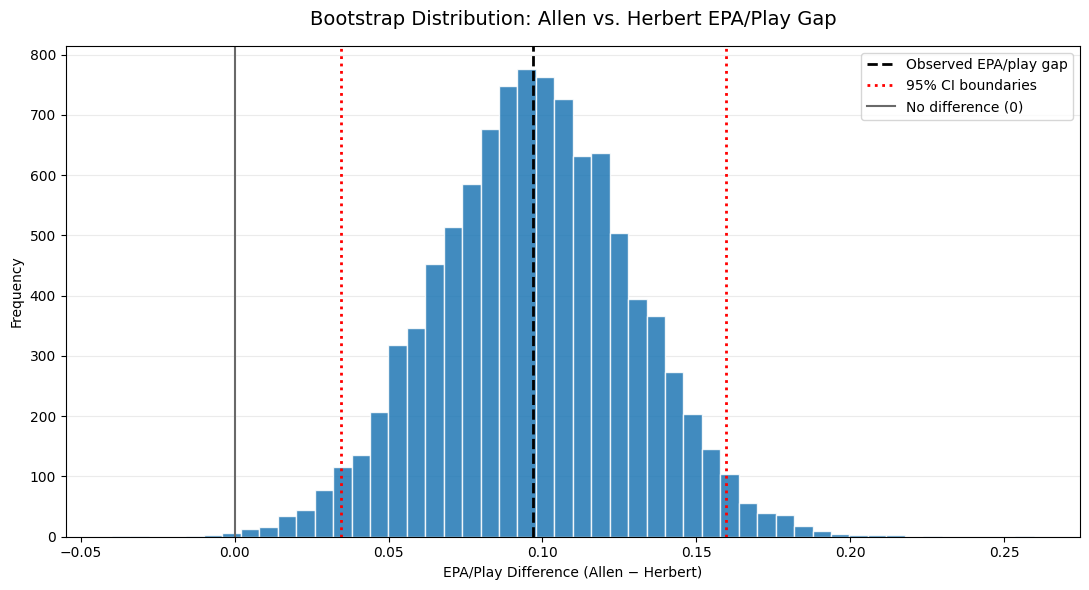

In [26]:
fig, ax = plt.subplots(figsize=(11, 6))

ax.hist(
    bootstrap_results["bootstrap_gaps"],
    bins=50,
    edgecolor="white",
    alpha=0.85
)

ax.axvline(
    bootstrap_results["observed_gap"],
    color="black",
    linestyle="--",
    linewidth=2,
    label="Observed EPA/play gap"
)

ax.axvline(
    bootstrap_results["lower_95"],
    color="red",
    linestyle=":",
    linewidth=2,
    label="95% CI boundaries"
)

ax.axvline(
    bootstrap_results["upper_95"],
    color="red",
    linestyle=":",
    linewidth=2
)

ax.axvline(
    0,
    color="dimgray",
    linestyle="-",
    linewidth=1.5,
    label="No difference (0)"
)

ax.set_title(
    "Bootstrap Distribution: Allen vs. Herbert EPA/Play Gap",
    fontsize=14,
    pad=15
)

ax.set_xlabel("EPA/Play Difference (Allen − Herbert)")
ax.set_ylabel("Frequency")

ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()